# 04 · AMT multi-instrumento (ruta orquestal)

**Fase 0.** Transcribir un conjunto clásico y saber **qué instrumento** tocó cada nota.

El plan es probar MuScriptor (o MT3 / YourMT3 como baseline), pero antes hay que verificar sus licencias y la memoria de GPU que necesitan (`docs/modelos.md`):

- [ ] Licencia del **código** de MuScriptor.
- [ ] Licencia de los **pesos** (¿permite uso en una app pública?).
- [ ] VRAM necesaria para inferencia y duración máxima por chunk.
- [ ] Cómo se condiciona por instrumentos (formato de entrada).
- [ ] Si falla alguno: fallback a YourMT3 / MT3.

Mientras tanto, este notebook mide el **modelo base** de la ruta orquestal del pipeline (`basic-pitch-assign`): Basic Pitch sobre la mezcla y asignación de cada nota a un instrumento por registro (`transcription.assign_notes`). Es la vara contra la que se comparará MuScriptor.

Usa grabaciones reales que descarga `npm run local:real-audio` en `data/real/` (no se suben al repo):

- **MUSDB18, extractos de 7 s** ([Zenodo](https://zenodo.org/records/3270814), CC BY 4.0): 144 fragmentos reales de rock y pop **con sus stems verdaderos** (voz, batería, bajo, resto).
- **TRIOS** ([Zenodo](https://zenodo.org/records/6797837), CC BY-NC-SA 2.0 UK): cinco tríos (Brahms, Lussier, Mozart, Schubert y *Take Five*) grabados instrumento por instrumento, **con el MIDI alineado**.

No hay grabaciones abiertas de orquesta completa con la verdad nota por nota (URMP y Bach10 piden registro); TRIOS es lo más cercano: instrumentos de orquesta reales, en grupos de tres.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, "..")  # repo root: src.*

import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
from IPython.display import Audio, display

REAL = Path("../data/real")  # npm run local:real-audio
OUTPUTS = Path("../outputs")
SR = 22050

import pretty_midi

from src.contract import instruments as catalog
from src.evaluation import datasets, metrics
from src.pipeline import symbolic, transcription

PIECES = ["brahms", "lussier", "mozart", "schubert"]
tracks = {p: datasets.trios_track(REAL / "trios" / p) for p in PIECES}
for p, t in tracks.items():
    print(f"{p:9s}", {catalog.get(i).name: len(n) for i, n in t.notes.items()})

brahms    {'Corno en Fa': 42, 'Piano': 264, 'Violín': 49}
lussier   {'Fagot': 65, 'Piano': 119, 'Trompeta en Si♭': 24}
mozart    {'Clarinete en Si♭': 69, 'Piano': 146, 'Viola': 32}
schubert  {'Violonchelo': 53, 'Piano': 292, 'Violín': 57}


## 1. Techo: cada instrumento aislado

Basic Pitch sobre la pista **real aislada** de cada instrumento, contra su MIDI. Es lo mejor que puede dar la ruta orquestal con este transcriptor (sin mezcla ni asignación), y mide la calidad de la alineación del MIDI.

In [2]:
def transcribe(path, instruments):
    pitched = [catalog.get(i) for i in instruments]
    return transcription.basic_pitch(path, min(i.low for i in pitched), max(i.high for i in pitched))

ceiling = {}
for p, t in tracks.items():
    for inst, notes in t.notes.items():
        est = symbolic.prepare(transcribe(t.stems[inst][0], [inst]), catalog.get(inst))
        ceiling[(p, inst)] = metrics.note_f1(notes, est)["f1"]
        print(f"{p:9s} {catalog.get(inst).name:14s} F1 aislado = {ceiling[(p, inst)]:.2f}")

Predicting MIDI for ../data/real/trios/brahms/horn.wav...


brahms    Corno en Fa    F1 aislado = 0.60
Predicting MIDI for ../data/real/trios/brahms/piano.wav...


brahms    Piano          F1 aislado = 0.69
Predicting MIDI for ../data/real/trios/brahms/violin.wav...


brahms    Violín         F1 aislado = 0.66
Predicting MIDI for ../data/real/trios/lussier/bassoon.wav...


lussier   Fagot          F1 aislado = 0.80
Predicting MIDI for ../data/real/trios/lussier/piano.wav...


...

mozart    Piano          F1 aislado = 0.79
Predicting MIDI for ../data/real/trios/mozart/viola.wav...


mozart    Viola          F1 aislado = 0.56
Predicting MIDI for ../data/real/trios/schubert/cello.wav...


schubert  Violonchelo    F1 aislado = 0.68
Predicting MIDI for ../data/real/trios/schubert/piano.wav...


schubert  Piano          F1 aislado = 0.78
Predicting MIDI for ../data/real/trios/schubert/violin.wav...


schubert  Violín         F1 aislado = 0.61


## 2. Mezcla: encontrar las notas y asignarlas

Lo que hace el pipeline: Basic Pitch sobre la mezcla, acotado al rango conjunto de los instrumentos pedidos; `assign_notes` reparte cada acorde por programación dinámica; `symbolic.prepare` limpia. Se reporta el F1 **sin instrumento** (¿encontró las notas?) y el **multi-instrument F1** (nota + instrumento).

In [3]:
def evaluate(track, instruments, mix_notes=None):
    mix_notes = mix_notes if mix_notes is not None else transcribe(track.mix, instruments)
    assigned = transcription.assign_notes(mix_notes, instruments)
    cleaned = {i: symbolic.prepare(n, catalog.get(i)) for i, n in assigned.items()}
    all_truth = [n for notes in track.notes.values() for n in notes]
    return {
        "agnostic": metrics.note_f1(all_truth, mix_notes)["f1"],
        "multi": metrics.multi_instrument_f1(track.notes, cleaned)["f1"],
        "per": {i: metrics.note_f1(track.notes.get(i, []), cleaned.get(i, []))["f1"] for i in instruments},
        "estimate": cleaned,
        "mix_notes": mix_notes,
    }

results = {p: evaluate(t, list(t.notes)) for p, t in tracks.items()}
for p, r in results.items():
    per = "  ".join(f"{catalog.get(i).name}={f:.2f}" for i, f in r["per"].items())
    print(f"{p:9s} sin instrumento F1={r['agnostic']:.2f} · multi-instrument F1={r['multi']:.2f} · {per}")
print(f"\nmedia: sin instrumento={np.mean([r['agnostic'] for r in results.values()]):.2f} · "
      f"multi-instrument={np.mean([r['multi'] for r in results.values()]):.2f}")

Predicting MIDI for ../data/real/trios/brahms/mix.wav...


Predicting MIDI for ../data/real/trios/lussier/mix.wav...
Predicting MIDI for ../data/real/trios/mozart/mix.wav...


Predicting MIDI for ../data/real/trios/schubert/mix.wav...


brahms    sin instrumento F1=0.60 · multi-instrument F1=0.35 · Corno en Fa=0.00  Piano=0.48  Violín=0.19
lussier   sin instrumento F1=0.57 · multi-instrument F1=0.30 · Fagot=0.31  Piano=0.31  Trompeta en Si♭=0.23
mozart    sin instrumento F1=0.72 · multi-instrument F1=0.57 · Clarinete en Si♭=0.60  Piano=0.69  Viola=0.20
schubert  sin instrumento F1=0.64 · multi-instrument F1=0.25 · Violonchelo=0.18  Piano=0.31  Violín=0.10

media: sin instrumento=0.63 · multi-instrument=0.37


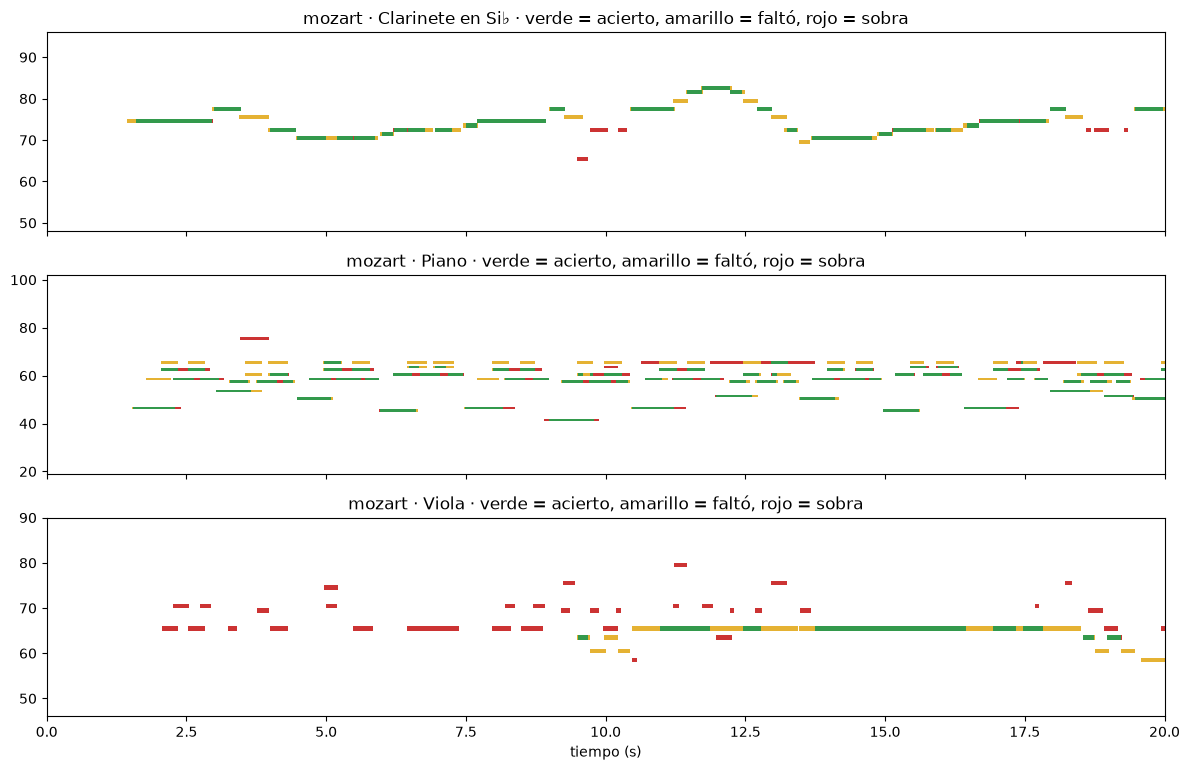

In [4]:
FS, T0, T1 = 50, 0, 20

def roll(notes):
    r = np.zeros((128, (T1 - T0) * FS), dtype=bool)
    for n in notes:
        a, b = int((n.start - T0) * FS), int((min(n.end, T1) - T0) * FS)
        if b > 0 and a < r.shape[1]:
            r[n.pitch, max(a, 0):b] = True
    return r

piece = "mozart"
t, r = tracks[piece], results[piece]
fig, axes = plt.subplots(len(t.notes), 1, figsize=(12, 2.6 * len(t.notes)), sharex=True)
for ax, inst in zip(axes, t.notes):
    ref, est = roll(t.notes[inst]), roll(r["estimate"].get(inst, []))
    image = np.ones((128, ref.shape[1], 3))
    image[ref & est] = (0.2, 0.6, 0.3)   # verde: acierto
    image[ref & ~est] = (0.9, 0.7, 0.2)  # amarillo: faltó
    image[~ref & est] = (0.8, 0.2, 0.2)  # rojo: sobra (o es de otro instrumento)
    ax.imshow(image, aspect="auto", origin="lower", extent=[T0, T1, 0, 128], interpolation="nearest")
    c = catalog.get(inst)
    ax.set_ylim(c.low - 2, min(c.high, 100) + 2)
    ax.set_title(f"{piece} · {c.name} · verde = acierto, amarillo = faltó, rojo = sobra")
axes[-1].set_xlabel("tiempo (s)")
plt.tight_layout()
plt.show()

## 3. ¿Adónde van las notas de cada instrumento?

Matriz de confusión: de las notas verdaderas de cada instrumento que el modelo encontró (onset ±50 ms y altura), a qué instrumento las asignó.

In [5]:
from mir_eval.transcription import match_notes
from src.evaluation.metrics import note_arrays

for p, t in tracks.items():
    instruments = list(t.notes)
    est = results[p]["estimate"]
    flat = [(i, n) for i in instruments for n in est.get(i, [])]
    est_iv, est_p = note_arrays([n for _, n in flat])
    print(f"\n{p} (filas = verdad, columnas = asignado)")
    print(" " * 16 + "".join(f"{catalog.get(i).name[:10]:>12s}" for i in instruments))
    for i in instruments:
        ref_iv, ref_p = note_arrays(t.notes[i])
        matched = match_notes(ref_iv, ref_p, est_iv, est_p, onset_tolerance=0.05, offset_ratio=None)
        counts = [sum(1 for _, k in matched if flat[k][0] == j) for j in instruments]
        print(f"{catalog.get(i).name[:14]:16s}" + "".join(f"{c:12d}" for c in counts) + f"   de {len(t.notes[i])}")


brahms (filas = verdad, columnas = asignado)
                  Corno en F       Piano      Violín
Corno en Fa                0          24           5   de 42
Piano                     41         123          24   de 264
Violín                     2           8          14   de 49

lussier (filas = verdad, columnas = asignado)
                       Fagot       Piano  Trompeta e
Fagot                     15          16           0   de 65
Piano                     14          37          19   de 119
Trompeta en Si             0          12           6   de 24

mozart (filas = verdad, columnas = asignado)
                  Clarinete        Piano       Viola
Clarinete en S            43           6           8   de 69
Piano                      1         104          25   de 146
Viola                      0           8          11   de 32

schubert (filas = verdad, columnas = asignado)
                  Violonchel       Piano      Violín
Violonchelo               17          19         

## 4. ¿Qué pasa si se piden otros instrumentos?

La asignación es por registro, no por timbre: si el usuario pide instrumentos que no suenan, o se olvida de uno, las notas se reparten igual.

In [6]:
t = tracks["mozart"]
mix_notes = results["mozart"]["mix_notes"]
scenarios = {
    "los correctos (clarinete, viola, piano)": ["clarinet", "viola", "piano"],
    "sin piano": ["clarinet", "viola"],
    "+ violonchelo (no suena)": ["clarinet", "viola", "piano", "cello"],
    "flauta en vez de clarinete": ["flute", "viola", "piano"],
}
for label, instruments in scenarios.items():
    r = evaluate(t, instruments, mix_notes)
    counts = ", ".join(f"{catalog.get(i).name}={len(n)}" for i, n in r["estimate"].items())
    print(f"{label:42s} multi-F1={r['multi']:.2f}   [{counts}]")

los correctos (clarinete, viola, piano)    multi-F1=0.57   [Piano=157, Viola=79, Clarinete en Si♭=74]
sin piano                                  multi-F1=0.23   [Viola=212, Clarinete en Si♭=78]
+ violonchelo (no suena)                   multi-F1=0.34   [Violonchelo=97, Piano=96, Viola=44, Clarinete en Si♭=74]
flauta en vez de clarinete                 multi-F1=0.40   [Piano=168, Viola=99, Flauta=49]


## 5. MuScriptor / YourMT3

Pendiente: no se integra hasta completar la lista de verificación de arriba en `docs/modelos.md`. El punto de integración en el pipeline ya existe (`A2S_MULTI_BACKEND`, `transcription.transcribe_mix`). Cuando esté, se repiten las celdas 2–4 con su salida y se compara con las tablas de abajo.

## Hallazgos

Ejecutado el 25 oct 2026 con los 4 tríos clásicos de TRIOS: Brahms (corno, violín, piano), Lussier (fagot, trompeta, piano), Mozart (clarinete, viola, piano) y Schubert (violín, violonchelo, piano). Son grabaciones reales con el MIDI alineado.

**1. Techo, cada instrumento aislado (F1 de onset):** clarinete 0,88, trompeta 0,85, fagot 0,80, piano 0,69–0,79, violonchelo 0,68, violín 0,61–0,66, corno 0,60, viola 0,56.

Los vientos se transcriben mejor que las cuerdas: las cuerdas tienen vibrato y ataques suaves, más difíciles de ubicar en ±50 ms. Una parte del error también puede venir de la alineación del MIDI.

**2. Mezcla, con lo que hace el pipeline:**

| Trío     | Sin instrumento | Multi-instrument |
| -------- | --------------- | ---------------- |
| Brahms   | 0,60            | 0,35             |
| Lussier  | 0,57            | 0,30             |
| Mozart   | 0,72            | 0,57             |
| Schubert | 0,64            | 0,25             |
| **Media**| **0,63**        | **0,37**         |

Basic Pitch encuentra aceptablemente las notas en la mezcla (0,63), pero **asignarlas por registro pierde casi la mitad**. El caso real es mucho peor que el coral sintético (0,55), donde las voces nunca se cruzaban.

**3. Matriz de confusión:** el problema es el piano.
- Ocupa todo el registro y es polifónico, así que absorbe notas de los demás: de las notas del corno que se encontraron, 24 fueron al piano y **ninguna** al corno (F1 0,00).
- A la vez le cede notas a quien comparta su registro: en Schubert, 64 notas del piano fueron al violonchelo y 50 al violín.
- En Mozart, antes de que entre la viola (segundo 9,5), las notas medias del piano se asignan a la viola (rojo en el piano-roll).

El clarinete de Mozart, que está solo en su registro agudo, sale bien (0,60).

**4. Pedir otros instrumentos (Mozart):**

| Instrumentos pedidos          | Multi-instrument F1 |
| ----------------------------- | ------------------- |
| Los correctos                 | 0,57                |
| Sin piano                     | 0,23                |
| + violonchelo (no suena)      | 0,34                |
| Flauta en vez de clarinete    | 0,40                |

Sin piano, la viola recibe 212 notas, casi todo el piano.

**Conclusiones:**

1. **Asignar por registro no sirve para música real con piano** ni con instrumentos que comparten registro. Sirve, a lo sumo, para conjuntos de vientos o cuerdas bien separados en tesitura. Esto sube la prioridad de un modelo que asigne por **timbre** (MuScriptor / YourMT3), una vez verificadas sus licencias y su VRAM.
2. Mientras tanto, el pipeline debería advertirlo con más fuerza cuando la ruta orquestal incluye piano o arpa, o cuando dos instrumentos pedidos se solapan mucho en tesitura.
3. Un experimento barato es separar el piano con Demucs (su stem funciona con piano real, notebook 03) y repartir solo el resto por registro.